# 05 · Results — tables and plots of the final runs

This notebook shows the results of step 04 and answers the question of the project: **which groups of features matter most to recognise illicit transactions?** Step 05 answers it by comparing the **menus**, that is models trained on different groups of features. How much a single feature matters *inside* a trained model (permutation importance, SHAP, Integrated Gradients, GNNExplainer) is step 06. The two steps complement each other: step 05 says whether a group **improves the performance**, step 06 says whether a model **uses it**.

**Runtime: CPU**, a few minutes. Nothing is trained: everything comes from the files of step 04.

**Inputs** (on Drive):
- `02-feature-menus/config.json` (menus, prevalences, bootstrap settings), `dataset.parquet` and `edges.parquet` (classes and neighbours, for section 9 only);
- `03-tuning/summary.csv` (the validation PR-AUC of the tuning);
- `04-final-runs/`: `summary/`, `bootstrap/`, `predictions/`, `curves/` and the two `determinism-*.csv` of the 132 triples (44 (menu, model) pairs × 3 seeds).

**Outputs:** tables in `05-plots/` (`results_table.csv`, `contrasts.csv`, `best_per_menu.csv`, `rescues.csv`) and plots in `plots/05_*.png`.

**The groups of features and the menus.**

| Group | Columns | Alone | Added to others (same model: menu with the group − menu without) |
|---|---|---|---|
| LF (Local features of Elliptic) | 93 | `local` | the base |
| AF (Aggregate features of Elliptic) | 72 | no menu | `local_agg` − `local` |
| Structure (families A + B + C) | 24 | `graph` | `local_agg_graph` − `local_agg`; `transparent` − `econ` |
| D (economic columns of Elliptic++) | 9 | `econ` | `transparent` − `graph` |
| Every transparent feature (A + B + C + D) | 33 | `transparent` | `transparent` − `local` (a swap: 33 named columns instead of 93 anonymous ones) |
| The graph alone, no feature | 0 | `none` (ChebNet, GIN) | against the random classifier |
| Message passing | — | — | GNN − MLP on the same menu |

**Metric.** The main metric is the **PR-AUC of the test** (average precision; a random classifier gets the test prevalence, 0.0531). The ROC-AUC goes to the appendix. At the threshold chosen on validation (best illicit F1), the tables also have the illicit F1, the **macro F1** $=\tfrac12(F_1^{\text{illicit}} + F_1^{\text{licit}})$ and the **MCC**
$$\mathrm{MCC} = \frac{tp\cdot tn - fp\cdot fn}{\sqrt{(tp+fp)(tp+fn)(tn+fp)(tn+fn)}} \in [-1, 1],$$
which is high only if the model is good on both classes. The licit F1 is always about 0.99 here, so the macro F1 moves half as much as the illicit F1.

**Uncertainty.** Two sources of noise: the **training** (another seed gives another model) and the **test sample** (another set of 9,866 transactions would give another number).
- A single value (one model on one menu) is shown as **mean ± standard deviation over the 3 seeds**.
- A **difference** between two menus of the same model, or between a GNN and the MLP on the same menu, gets **one 95% interval that counts both sources** (two-level bootstrap). Step 04 saved the PR-AUC of every triple on 1,000 resamples of the test, the same resamples for every triple. At resample $b$, three seeds are drawn at random with replacement for each side, $s_{b,1..3}$ and $s'_{b,1..3}$:
$$\Delta_b = \frac13\sum_{k=1}^{3}\mathrm{AP}_b(\text{side 1}, s_{b,k}) - \frac13\sum_{k=1}^{3}\mathrm{AP}_b(\text{side 2}, s'_{b,k}),$$
and the interval goes from the 2.5th to the 97.5th percentile of the 1,000 $\Delta_b$. Comparing on the same resamples removes the noise the two sides share (an easy test sample is easy for both); drawing the seeds adds the noise of the training. If the interval does not contain 0, the difference is **clear**. The standard deviations of the two sources are not averaged: they add up inside this one interval.

**One model per menu.** Plots and tables show every model. Where a single model must represent a menu (PR curves, top-k, `best_per_menu.csv`), it is the model with the highest **validation** PR-AUC (mean over the seeds), never the best on the test: choosing on the test would make its test number optimistic. `best_per_menu.csv` also shows the best model on the test, and whether the two coincide.

## 0. Setup

In [1]:
# Connect Google Drive: every input and output of the project lives in DATA_PATH.
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

DATA_PATH = Path('/content/drive/MyDrive/UNIVERSITA/block-crypto/data')
INPUT_DIR = DATA_PATH / '02-feature-menus'   # output of step 02
TUNING_DIR = DATA_PATH / '03-tuning'         # output of step 03
RUNS_DIR = DATA_PATH / '04-final-runs'       # output of step 04
OUT_DIR = DATA_PATH / '05-plots'             # tables of this notebook
PLOT_DIR = DATA_PATH / 'plots'               # every plot of the project

Mounted at /content/drive


In [2]:
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter
from PIL import Image
from sklearn.metrics import average_precision_score, precision_recall_curve

FORCE_RECOMPUTE = False   # True = write again the tables and plots that are already on Drive
DRAW_SEED = 0             # seed of the random choice of seeds in the two-level bootstrap
REFERENCE_SEED = 0        # the run shown when a plot needs one single run (fixed before seeing the results)
CURVE_GNN = 'sage'        # the GNN of the learning curves (fixed before seeing the results)
TOPK_KS = [100, 524, 987] # top-k of section 7: 1% of the test, the number of illicit in the test, 10% of the test

OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Colours of the report. Classes: red, blue, light grey. Models (section 1 only): the 8 categorical slots in a fixed
# order, checked with the colour validator (adjacent pairs pass for colour-blind readers). Groups of models
# (scatter plots): the first three slots, which pass for every pair. Magnitudes: one blue ramp, light = low.
# Single series: dark grey. Text always in ink colours.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
CLASS_COLOR = {'illicit': '#e34948', 'licit': '#2a78d6', 'unknown': '#d4d3cc'}
NEUTRAL = '#52514e'
MODELS = ['logreg', 'rf', 'xgb', 'mlp', 'sage', 'gatv2', 'cheb', 'gin']
MODEL_NAME = {'logreg': 'LogReg', 'rf': 'Random Forest', 'xgb': 'XGBoost', 'mlp': 'MLP', 'sage': 'GraphSAGE',
              'gatv2': 'GATv2', 'cheb': 'ChebNet', 'gin': 'GIN'}
MODEL_COLOR = dict(zip(MODELS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']))
GNNS = ['sage', 'gatv2', 'cheb']
GROUP_OF = {'logreg': 'LogReg, RF, XGBoost', 'rf': 'LogReg, RF, XGBoost', 'xgb': 'LogReg, RF, XGBoost', 'mlp': 'MLP',
            'sage': 'GNN', 'gatv2': 'GNN', 'cheb': 'GNN', 'gin': 'GNN'}
GROUP_COLOR = {'LogReg, RF, XGBoost': '#2a78d6', 'MLP': '#eb6834', 'GNN': '#1baf7a'}
SERIES_2 = ['#2a78d6', '#eb6834', '#1baf7a']   # two or three series that are not classes nor models
BLUE_RAMP = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7', '#3987e5', '#2a78d6', '#256abf',
             '#1c5cab', '#184f95', '#104281', '#0d366b']
BLUE_CMAP = LinearSegmentedColormap.from_list('blue', BLUE_RAMP)

SINGLE_GROUP = ['local', 'graph', 'econ', 'none']          # menus with one group of features (or none)
COMBINED = ['local_agg', 'transparent', 'local_agg_graph']  # menus that combine groups
MENU_ORDER = SINGLE_GROUP + COMBINED
FEATURE_MENUS = [m for m in MENU_ORDER if m != 'none']
MENU_LABEL = {'local': 'local\n(LF)', 'graph': 'graph\n(A+B+C)', 'econ': 'econ\n(D)', 'none': 'none\n(graph only)',
              'local_agg': 'local_agg\n(LF+AF)', 'transparent': 'transparent\n(A+B+C+D)',
              'local_agg_graph': 'local_agg_graph\n(LF+AF+A+B+C)'}
ADDED = [   # (question, menu with the group, menu without it)
    ('AF added to LF', 'local_agg', 'local'),
    ('structure (A+B+C) added to LF+AF', 'local_agg_graph', 'local_agg'),
    ('structure (A+B+C) added to D', 'transparent', 'econ'),
    ('D added to the structure', 'transparent', 'graph'),
    ('33 transparent instead of 93 LF', 'transparent', 'local'),
]

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'text.color': INK, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.edgecolor': AXIS, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
})
MAX_PIXELS, MAX_KB = (1200, 800), 200


def atomic(path, write):
    """Write through a temporary file, then rename it: no half-written file on Drive."""
    tmp = path.with_name(path.name + '.tmp')
    write(tmp)
    os.replace(tmp, path)


def save_table(df, name, show=True):
    """Show a table and write it to OUT_DIR (unless it is already there)."""
    if show:
        display(df)
    path = OUT_DIR / name
    if path.exists() and not FORCE_RECOMPUTE:
        print(f'{name} is already on Drive: not overwritten.')
    else:
        atomic(path, lambda tmp: df.to_csv(tmp, index=False, float_format='%.6g'))
        print(f'{name} written.')


def save_png(fig, name):
    """Show a figure and save it at 100 dpi: at most 1200 x 800 pixels and 200 KB
    (a 256-colour PNG if the full-colour one is too big). An existing plot is not overwritten."""
    width, height = fig.get_size_inches() * 100
    assert width <= MAX_PIXELS[0] + 0.5 and height <= MAX_PIXELS[1] + 0.5, 'figure too large'
    path = PLOT_DIR / name
    if path.exists() and not FORCE_RECOMPUTE:
        plt.show()
        plt.close(fig)
        print(f'{name} is already on Drive: not overwritten.')
        return
    tmp = path.with_name(path.name + '.tmp')
    fig.savefig(tmp, dpi=100, format='png')
    plt.show()
    plt.close(fig)
    if tmp.stat().st_size > MAX_KB * 1000:
        with Image.open(tmp) as image:
            small = image.convert('RGB').quantize(256)
        small.save(tmp, format='PNG', optimize=True)
    size = tmp.stat().st_size / 1000
    assert size <= MAX_KB, f'{name}: {size:.0f} KB'
    os.replace(tmp, path)
    print(f'{name} written ({size:.0f} KB).')


def titles(fig, title, subtitle, top=0.97):
    fig.text(0.02, top, title, fontsize=13, weight='bold', ha='left', va='top')
    fig.text(0.02, top - 0.045 * 8 / fig.get_size_inches()[1], subtitle, fontsize=9, color=INK_2,
             ha='left', va='top', linespacing=1.4)


def text_color_on(rgba):
    """White text on dark cells, ink on light ones."""
    r, g, b = rgba[:3]
    return 'white' if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else INK


def light_grid(ax, axis='y'):
    ax.grid(axis=axis, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)

## 1. Load the results of step 04

The notebook stops if a triple is missing, or if the triples were written by different versions of the shared code or of `config.json`. It also prints the reproducibility check of step 04 in one line (the details are in the two `determinism-*.csv`).

In [4]:
config = json.loads((INPUT_DIR / 'config.json').read_text(encoding='utf-8'))
SEEDS = config['final_runs']['seeds']
PAIRS = [tuple(p) for p in config['pairs']]
PAIR_SET = set(PAIRS)
PREVALENCE = config['labels']['prevalence']
LOW, HIGH = config['evaluation']['bootstrap']['interval']


def triple_id(menu, model, seed):
    return f'{menu}__{model}__seed{seed}'


def models_of(menu):
    return [m for m in MODELS if (menu, m) in PAIR_SET]


records = {}
for path in sorted((RUNS_DIR / 'summary').glob('*.json')):
    r = json.loads(path.read_text(encoding='utf-8'))
    records[(r['menu'], r['model'], r['seed'])] = r
expected = [(menu, model, seed) for menu, model in PAIRS for seed in SEEDS]
missing = [triple_id(*t) for t in expected if t not in records]
assert not missing, f'{len(missing)} triples are missing in 04-final-runs/summary (e.g. {missing[:3]}): finish step 04 first'
code_versions = {records[t]['shared_code_version'] for t in expected}
config_versions = {records[t]['config_version'] for t in expected}
assert len(code_versions) == 1, f'the triples were written by different shared code versions: {code_versions}'
assert config_versions == {config['version']}, f'config.json versions: {config_versions}'
print(f'{len(expected)} triples ({len(PAIRS)} pairs x {len(SEEDS)} seeds), shared code version {code_versions.pop()}, '
      f'config version {config["version"]}.')


def flat(r):
    """The numbers of one triple used below."""
    m = r['metrics']
    test, val, train = m['by_split']['test'], m['by_split']['val'], m['by_split']['train']
    at = test['at_best_val_f1']
    row = {'menu': r['menu'], 'model': r['model'], 'seed': r['seed'],
           'test_ap': test['average_precision'], 'test_roc': test['roc_auc'],
           'val_ap': val['average_precision'], 'val_roc': val['roc_auc'], 'train_ap': train['average_precision'],
           'oob_ap': r['training'].get('oob_average_precision'), 'tuning_val_ap': r['val_average_precision_tuning'],
           'best_epoch': r['training'].get('best_epoch'), 'threshold': m['thresholds']['best_val_f1'],
           'f1_illicit': at['f1_illicit'], 'f1_macro': at['f1_macro'], 'mcc': at['mcc'],
           'precision_illicit': at['precision_illicit'], 'recall_illicit': at['recall_illicit']}
    for k in TOPK_KS:
        entry = next(e for e in m['top_k_test'].values() if e['k'] == k)
        row[f'recall_at_{k}'], row[f'precision_at_{k}'] = entry['recall'], entry['precision']
    return row


RUNS = pd.DataFrame([flat(records[t]) for t in expected])
VALUE_COLUMNS = [c for c in RUNS.columns if c not in ('menu', 'model', 'seed')]
STATS = RUNS.groupby(['menu', 'model'])[VALUE_COLUMNS].agg(['mean', 'std'])
STATS.columns = [f'{a}_{b}' for a, b in STATS.columns]

# the 1,000 bootstrap values of every triple: one (seeds x resamples) array per pair and metric
BOOT = {}
for menu, model in PAIRS:
    tables = [pd.read_csv(RUNS_DIR / 'bootstrap' / f'{triple_id(menu, model, s)}.csv') for s in SEEDS]
    assert all(np.array_equal(t['resample'], tables[0]['resample']) for t in tables)
    BOOT[(menu, model)] = {metric: np.vstack([t[metric].to_numpy() for t in tables])
                           for metric in ['average_precision', 'roc_auc']}
print('Bootstrap values loaded:', len(BOOT), 'pairs x', BOOT[PAIRS[0]]['average_precision'].shape, '(seeds x resamples).')

# the reproducibility check of step 04, in one line
parts = []
for nb in ['cpu', 'gpu']:
    path = RUNS_DIR / f'determinism-{nb}.csv'
    if path.exists():
        det = pd.read_csv(path)
        same = det[det['check'] == 'same seed twice']
        parts.append(f"{nb}: same seed twice, largest score difference {same['max_abs_score_difference'].max():.1e} "
                     f"({', '.join(same['model'])})")
        seeds = det[det['check'] == 'seeds 0, 1, 2']
        if len(seeds):
            parts.append(f"LogReg seeds 0-2 identical on {len(seeds)} menus "
                         f"(largest difference {seeds['max_abs_score_difference'].max():.1e})")
print('Reproducibility (step 04) ·', ' · '.join(parts) if parts else 'determinism files not found')

132 triples (44 pairs x 3 seeds), shared code version 1, config version 1.
Bootstrap values loaded: 44 pairs x (3, 1000) (seeds x resamples).
Reproducibility (step 04) · cpu: same seed twice, largest score difference 2.2e-16 (logreg, rf) · LogReg seeds 0-2 identical on 6 menus (largest difference 0.0e+00) · gpu: same seed twice, largest score difference 0.0e+00 (xgb, mlp, sage, gatv2, cheb, gin)


## 2. The bootstrap resamples, and the two-level interval

Step 04 drew the 1,000 resamples of the test from a fixed seed and saved only their PR-AUC and ROC-AUC. Here the same resamples are drawn again with the same function (`bootstrap_weights`, copied from step 04) and checked: the PR-AUC of one triple on the first resamples must equal the saved values. The resamples are needed for the **random classifier**: on resample $b$ its PR-AUC is the prevalence of that resample, so "the graph alone against chance" is also a paired difference.

Then the **toy tests** of the two-level interval:
- with three identical seeds, drawing seeds changes nothing: the interval must equal the simple paired interval;
- a synthetic model that is truly better by 0.10 must get a clear difference around 0.10; two models that differ only by noise must get an interval that contains 0.

In [5]:
def bootstrap_weights(n, resamples, seed):
    """Copy of the function of step 04: how many times each test row appears in each bootstrap resample."""
    rng = np.random.default_rng(seed)
    picks = rng.integers(0, n, size=(resamples, n))
    flat_picks = (picks + n * np.arange(resamples)[:, None]).ravel()
    return np.bincount(flat_picks, minlength=resamples * n).reshape(resamples, n).astype(np.int32)


boot_cfg = config['evaluation']['bootstrap']
first = expected[0]
saved = pd.read_parquet(RUNS_DIR / 'predictions' / f'{triple_id(*first)}.parquet')
test_rows = saved[saved['split'] == 'test']
Y_TEST = test_rows['y'].to_numpy().astype(int)
WEIGHTS = bootstrap_weights(len(Y_TEST), boot_cfg['resamples'], boot_cfg['seed'])
saved_boot = pd.read_csv(RUNS_DIR / 'bootstrap' / f'{triple_id(*first)}.csv')
for b in range(3):
    again = average_precision_score(Y_TEST, test_rows['score'].to_numpy(), sample_weight=WEIGHTS[b])
    assert abs(again - saved_boot['average_precision'][b]) < 1e-9, 'the resamples differ from those of step 04'
CHANCE = {'average_precision': WEIGHTS @ Y_TEST / WEIGHTS.sum(axis=1),   # PR-AUC of a random classifier, per resample
          'roc_auc': np.full(len(WEIGHTS), 0.5)}
print(f'Resamples of step 04 reproduced: {len(WEIGHTS)} x {len(Y_TEST):,} test rows. Prevalence over the resamples: '
      f'{CHANCE["average_precision"].mean():.4f} (from {CHANCE["average_precision"].min():.4f} to {CHANCE["average_precision"].max():.4f}).')


def two_level(values_a, values_b=None, chance=None, seed=DRAW_SEED):
    """Two-level bootstrap: values are (seeds x resamples) arrays. At every resample b, the seeds of each side are
    drawn at random with replacement and averaged; the result is one value per resample: side a, a - b, or a - chance."""
    rng = np.random.default_rng(seed)
    columns = np.arange(values_a.shape[1])[:, None]
    pick_a = rng.integers(0, values_a.shape[0], size=(values_a.shape[1], values_a.shape[0]))
    side_a = values_a[pick_a, columns].mean(axis=1)
    if values_b is not None:
        pick_b = rng.integers(0, values_b.shape[0], size=(values_b.shape[1], values_b.shape[0]))
        return side_a - values_b[pick_b, columns].mean(axis=1)
    return side_a if chance is None else side_a - chance


def interval(values):
    low, high = np.percentile(values, [LOW, HIGH])
    return float(low), float(high)


# toy tests
rng = np.random.default_rng(0)
a1, b1 = 0.80 + 0.02 * rng.standard_normal(1000), 0.75 + 0.02 * rng.standard_normal(1000)
same_seeds = two_level(np.vstack([a1] * 3), np.vstack([b1] * 3))
assert np.allclose(same_seeds, a1 - b1), 'identical seeds: the two-level interval must be the paired one'
assert np.allclose(interval(same_seeds), interval(a1 - b1), rtol=0, atol=1e-12)
shared = 0.03 * rng.standard_normal(1000)                      # the test sample: shared by the two sides
better = 0.80 + shared + 0.01 * rng.standard_normal((3, 1000))
worse = 0.70 + shared + 0.01 * rng.standard_normal((3, 1000))
twin = 0.80 + shared + 0.01 * rng.standard_normal((3, 1000))
lo, hi = interval(two_level(better, worse))
assert lo > 0.07 and hi < 0.13, (lo, hi)
lo2, hi2 = interval(two_level(better, twin))
assert lo2 < 0 < hi2, (lo2, hi2)
print(f'Toy tests passed: identical seeds give the paired interval; true difference 0.10 -> [{lo:.3f}, {hi:.3f}]; '
      f'no difference -> [{lo2:.3f}, {hi2:.3f}].')

Resamples of step 04 reproduced: 1000 x 9,866 test rows. Prevalence over the resamples: 0.0531 (from 0.0464 to 0.0604).
Toy tests passed: identical seeds give the paired interval; true difference 0.10 -> [0.081, 0.121]; no difference -> [-0.020, 0.022].


## 3. Tables

- **`results_table.csv`**: one row per model and menu. Mean and standard deviation over the seeds of PR-AUC and ROC-AUC of the test and, at the threshold chosen on validation, of the illicit F1, the macro F1, the MCC, precision and recall; the validation PR-AUC; and the **95% interval of the test PR-AUC that counts both test sample and seeds** (two-level bootstrap, one side only).
- **`contrasts.csv`**: one row per comparison, model and metric (PR-AUC and ROC-AUC): the mean of each side over the seeds, the difference, its two-level interval, the standard deviation over the seeds of each side, and whether the difference is clear. Three kinds: a group added to others (same model, two menus), message passing (GNN − MLP on the same menu), the graph alone against the random classifier.
- **`best_per_menu.csv`**: for every menu, the model with the best validation PR-AUC and its test numbers; the best model on the test; whether they coincide.

In [6]:
rows = []
for menu in MENU_ORDER:
    for model in models_of(menu):
        s = STATS.loc[(menu, model)]
        row = {'menu': menu, 'model': model, 'seeds': len(SEEDS)}
        for col in ['test_ap', 'test_roc', 'f1_illicit', 'f1_macro', 'mcc', 'precision_illicit', 'recall_illicit', 'val_ap']:
            row[f'{col}_mean'], row[f'{col}_std'] = s[f'{col}_mean'], s[f'{col}_std']
        row['test_ap_interval_low'], row['test_ap_interval_high'] = interval(two_level(BOOT[(menu, model)]['average_precision']))
        rows.append(row)
RESULTS = pd.DataFrame(rows)
save_table(RESULTS.round(4), 'results_table.csv')

,menu,model,seeds,test_ap_mean,test_ap_std,test_roc_mean,test_roc_std,f1_illicit_mean,f1_illicit_std,f1_macro_mean,...,mcc_mean,mcc_std,precision_illicit_mean,precision_illicit_std,recall_illicit_mean,recall_illicit_std,val_ap_mean,val_ap_std,test_ap_interval_low,test_ap_interval_high
0,local,logreg,3,0.1809,0.0000,0.8082,0.0000,0.4042,0.0000,0.6786,...,0.3774,0.0000,0.3177,0.0000,0.5553,0.0000,0.5237,0.0000,0.1614,0.2042
1,local,rf,3,0.6250,0.0016,0.8196,0.0053,0.6631,0.0067,0.8238,...,0.6654,0.0085,0.8447,0.0174,0.5458,0.0038,0.9539,0.0002,0.5865,0.6620
2,local,xgb,3,0.6345,0.0020,0.8651,0.0034,0.6630,0.0051,0.8239,...,0.6694,0.0057,0.8683,0.0108,0.5363,0.0050,0.9560,0.0008,0.5981,0.6711
3,local,mlp,3,0.3088,0.0348,0.7957,0.0061,0.5137,0.0323,0.7420,...,0.4863,0.0342,0.4822,0.0608,0.5528,0.0040,0.8919,0.0025,0.2646,0.3589
4,local,sage,3,0.3144,0.0108,0.8482,0.0016,0.4999,0.0111,0.7342,...,0.4717,0.0114,0.4536,0.0191,0.5573,0.0138,0.9157,0.0070,0.2797,0.3560
5,local,gatv2,3,0.3831,0.1522,0.8181,0.0175,0.4216,0.0422,0.6907,...,0.3903,0.0422,0.3631,0.0620,0.5083,0.0123,0.8177,0.0674,0.2196,0.5130
6,local,cheb,3,0.3565,0.0314,0.8688,0.0019,0.5168,0.0109,0.7436,...,0.4893,0.0111,0.4791,0.0242,0.5617,0.0079,0.9134,0.0088,0.3111,0.4089
7,graph,logreg,3,0.1339,0.0000,0.7106,0.0000,0.1978,0.0000,0.5556,...,0.1501,0.0000,0.1360,0.0000,0.3626,0.0000,0.2437,0.0000,0.1149,0.1546
8,graph,rf,3,0.1454,0.0004,0.7266,0.0032,0.2535,0.0091,0.5990,...,0.2083,0.0104,0.2068,0.0057,0.3308,0.0421,0.3515,0.0041,0.1261,0.1676
9,graph,xgb,3,0.1665,0.0070,0.7342,0.0178,0.2356,0.0142,0.5877,...,0.1894,0.0167,0.1880,0.0206,0.3232,0.0516,0.3382,0.0044,0.1422,0.1969


results_table.csv written.


In [7]:
def contrast_row(kind, question, model, side_a, side_b, metric):
    """side_a and side_b are (menu, model) pairs; side_b = None means the random classifier."""
    col = {'average_precision': 'test_ap', 'roc_auc': 'test_roc'}[metric]
    mean_a, std_a = STATS.loc[side_a, f'{col}_mean'], STATS.loc[side_a, f'{col}_std']
    if side_b is None:
        mean_b, std_b = (PREVALENCE['test'] if metric == 'average_precision' else 0.5), 0.0
        deltas = two_level(BOOT[side_a][metric], chance=CHANCE[metric])
    else:
        mean_b, std_b = STATS.loc[side_b, f'{col}_mean'], STATS.loc[side_b, f'{col}_std']
        deltas = two_level(BOOT[side_a][metric], BOOT[side_b][metric])
    low, high = interval(deltas)
    return {'kind': kind, 'question': question, 'model': model,
            'side_a': '__'.join(side_a), 'side_b': 'random classifier' if side_b is None else '__'.join(side_b),
            'metric': metric, 'mean_a': mean_a, 'mean_b': mean_b, 'difference': mean_a - mean_b,
            'interval_low': low, 'interval_high': high, 'std_seeds_a': std_a, 'std_seeds_b': std_b,
            'clear': bool(low > 0 or high < 0)}


rows = []
for metric in ['average_precision', 'roc_auc']:
    for question, with_group, without in ADDED:
        for model in models_of(with_group):
            if (without, model) in PAIR_SET:
                rows.append(contrast_row('group added', question, model, (with_group, model), (without, model), metric))
    for menu in FEATURE_MENUS:
        for gnn in GNNS:
            rows.append(contrast_row('message passing', f'{MODEL_NAME[gnn]} - MLP', gnn, (menu, gnn), (menu, 'mlp'), metric))
    for model in models_of('none'):
        rows.append(contrast_row('graph vs chance', 'graph alone - random classifier', model, ('none', model), None, metric))
CONTRASTS = pd.DataFrame(rows)
save_table(CONTRASTS.round(5), 'contrasts.csv', show=False)
display(CONTRASTS[CONTRASTS['metric'] == 'average_precision'].drop(columns='metric').round(4))

contrasts.csv written.


,kind,question,model,side_a,side_b,mean_a,mean_b,difference,interval_low,interval_high,std_seeds_a,std_seeds_b,clear
0,group added,AF added to LF,logreg,local_agg__logreg,local__logreg,0.3506,0.1809,0.1697,0.1395,0.2027,0.0000,0.0000,True
1,group added,AF added to LF,rf,local_agg__rf,local__rf,0.6377,0.6250,0.0127,0.0051,0.0199,0.0018,0.0016,True
2,group added,AF added to LF,xgb,local_agg__xgb,local__xgb,0.6512,0.6345,0.0167,0.0079,0.0269,0.0006,0.0020,True
3,group added,AF added to LF,mlp,local_agg__mlp,local__mlp,0.4206,0.3088,0.1119,0.0626,0.1589,0.0214,0.0348,True
4,group added,AF added to LF,sage,local_agg__sage,local__sage,0.5206,0.3144,0.2062,0.1537,0.2590,0.0442,0.0108,True
5,group added,AF added to LF,gatv2,local_agg__gatv2,local__gatv2,0.5061,0.3831,0.1230,0.0003,0.2960,0.0405,0.1522,True
6,group added,AF added to LF,cheb,local_agg__cheb,local__cheb,0.4730,0.3565,0.1165,0.0654,0.1623,0.0123,0.0314,True
7,group added,structure (A+B+C) added to LF+AF,logreg,local_agg_graph__logreg,local_agg__logreg,0.3673,0.3506,0.0167,0.0081,0.0255,0.0000,0.0000,True
8,group added,structure (A+B+C) added to LF+AF,rf,local_agg_graph__rf,local_agg__rf,0.6375,0.6377,-0.0002,-0.0033,0.0031,0.0019,0.0018,False
9,group added,structure (A+B+C) added to LF+AF,xgb,local_agg_graph__xgb,local_agg__xgb,0.6518,0.6512,0.0006,-0.0042,0.0051,0.0037,0.0006,False


In [8]:
rows = []
for menu in MENU_ORDER:
    models = models_of(menu)
    chosen = max(models, key=lambda m: STATS.loc[(menu, m), 'val_ap_mean'])
    best_test = max(models, key=lambda m: STATS.loc[(menu, m), 'test_ap_mean'])
    s = STATS.loc[(menu, chosen)]
    low, high = interval(two_level(BOOT[(menu, chosen)]['average_precision']))
    rows.append({'menu': menu, 'chosen_on_validation': chosen, 'val_ap_mean': s['val_ap_mean'],
                 'test_ap_mean': s['test_ap_mean'], 'test_ap_std': s['test_ap_std'],
                 'test_ap_interval_low': low, 'test_ap_interval_high': high,
                 'test_roc_mean': s['test_roc_mean'], 'f1_illicit_mean': s['f1_illicit_mean'],
                 'f1_macro_mean': s['f1_macro_mean'], 'mcc_mean': s['mcc_mean'],
                 'best_on_test': best_test, 'best_on_test_ap_mean': STATS.loc[(menu, best_test), 'test_ap_mean'],
                 'same_model': chosen == best_test})
BEST = pd.DataFrame(rows)
CHOSEN = dict(zip(BEST['menu'], BEST['chosen_on_validation']))
save_table(BEST.round(4), 'best_per_menu.csv')

,menu,chosen_on_validation,val_ap_mean,test_ap_mean,test_ap_std,test_ap_interval_low,test_ap_interval_high,test_roc_mean,f1_illicit_mean,f1_macro_mean,mcc_mean,best_on_test,best_on_test_ap_mean,same_model
0,local,xgb,0.9560,0.6345,0.0020,0.5981,0.6711,0.8651,0.6630,0.8239,0.6694,xgb,0.6345,True
1,graph,sage,0.4747,0.2957,0.0052,0.2579,0.3355,0.7196,0.2895,0.6230,0.2488,gatv2,0.2968,False
2,econ,xgb,0.8139,0.4369,0.0177,0.3898,0.4879,0.7349,0.5672,0.7733,0.5569,gatv2,0.4750,False
3,none,cheb,0.3683,0.2182,0.0056,0.1823,0.2533,0.6793,0.1968,0.5732,0.1492,gin,0.2480,False
4,local_agg,xgb,0.9614,0.6512,0.0006,0.6140,0.6877,0.8843,0.7024,0.8445,0.7107,xgb,0.6512,True
5,transparent,xgb,0.7964,0.4224,0.0184,0.3747,0.4778,0.7465,0.5684,0.7737,0.5543,mlp,0.4863,False
6,local_agg_graph,xgb,0.9609,0.6518,0.0037,0.6129,0.6881,0.8853,0.7051,0.8460,0.7158,xgb,0.6518,True


best_per_menu.csv written.


## 4. Plot 1 — every model on every menu (`05_results_bars.png`)

Bars grouped by menu, one colour per model: the test PR-AUC, mean over the 3 seeds, with the standard deviation as a black line. First the menus with a single group (how much information each group has **alone**), then the menus that combine groups. The dashed line is the random classifier. Bars start from 0, so differences of one or two hundredths are hard to see here: the exact values are in plot 2, the differences with their interval in plots 3 and 4.

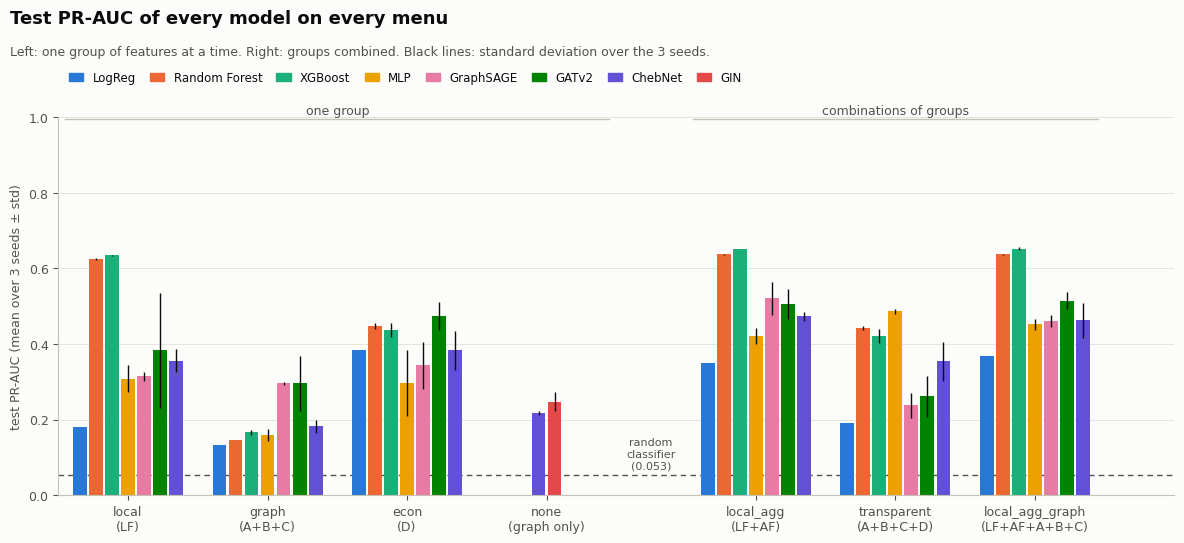

05_results_bars.png written (55 KB).


In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
fig.subplots_adjust(left=0.06, right=0.99, top=0.79, bottom=0.16)
width, x, ticks, labels = 0.115, 0.0, [], []
for block, menus in [('one group', SINGLE_GROUP), ('combinations of groups', COMBINED)]:
    start = x
    for menu in menus:
        models = models_of(menu)
        offsets = (np.arange(len(models)) - (len(models) - 1) / 2) * width
        for model, offset in zip(models, offsets):
            s = STATS.loc[(menu, model)]
            ax.bar(x + offset, s['test_ap_mean'], width * 0.86, color=MODEL_COLOR[model], zorder=2)
            ax.errorbar(x + offset, s['test_ap_mean'], yerr=s['test_ap_std'], fmt='none', ecolor=INK, elinewidth=1,
                        zorder=3)
        ticks.append(x)
        labels.append(MENU_LABEL[menu])
        x += 1
    ax.annotate(block, xy=((start + x - 1) / 2, 1.0), xycoords=ax.get_xaxis_transform(), ha='center', va='bottom',
                fontsize=9, color=INK_2)
    ax.plot([start - 0.45, x - 0.55], [0.995, 0.995], transform=ax.get_xaxis_transform(), color=AXIS, linewidth=1,
            clip_on=False)
    x += 0.5
ax.axhline(PREVALENCE['test'], color=INK_2, linewidth=1, linestyle=(0, (4, 3)), zorder=1)
gap_centre = len(SINGLE_GROUP) - 0.25          # the empty space between the two blocks of menus
ax.text(gap_centre, PREVALENCE['test'] + 0.012, f"random\nclassifier\n({PREVALENCE['test']:.3f})", ha='center',
        va='bottom', fontsize=8, color=INK_2)
ax.set_xticks(ticks, labels)
ax.set_xlim(-0.5, x - 0.5)
ax.set_ylim(0, 1)
ax.set_ylabel('test PR-AUC (mean over 3 seeds ± std)')
light_grid(ax)
ax.legend(handles=[Patch(color=MODEL_COLOR[m], label=MODEL_NAME[m]) for m in MODELS], ncol=8, frameon=False,
          loc='lower left', bbox_to_anchor=(0, 1.06), fontsize=8.5, handlelength=1.2, columnspacing=1.2)
titles(fig, 'Test PR-AUC of every model on every menu',
       'Left: one group of features at a time. Right: groups combined. Black lines: standard deviation over the 3 seeds.')
save_png(fig, '05_results_bars.png')

## 5. Plot 2 — the exact values (`05_results_heatmap.png`)

Rows: models; columns: menus. In every cell, the test PR-AUC as mean ± standard deviation over the seeds. One hue, **calibrated on the extremes** of the six menus with features: the lightest colour is the lowest value, the darkest the highest, so small differences stand out. The cells of `none` (no feature) are probably far below the others: they take the lightest colour, with their number written, so that they do not flatten the scale. Empty cells: the model does not run on that menu.

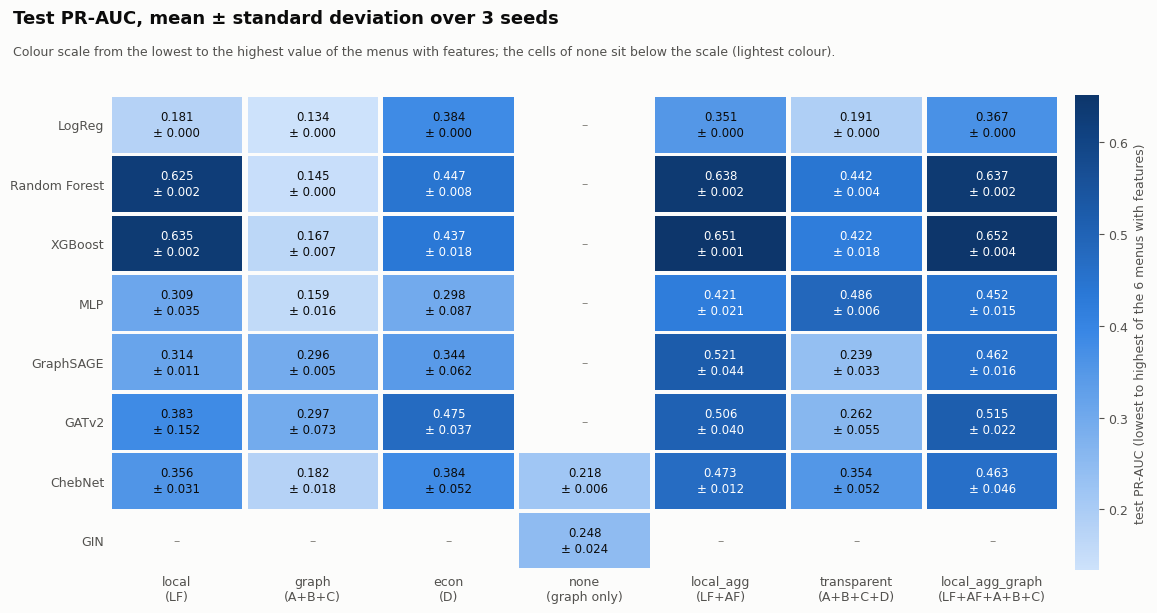

05_results_heatmap.png written (115 KB).


In [10]:
mean = np.full((len(MODELS), len(MENU_ORDER)), np.nan)
std = np.full_like(mean, np.nan)
for i, model in enumerate(MODELS):
    for j, menu in enumerate(MENU_ORDER):
        if (menu, model) in PAIR_SET:
            mean[i, j], std[i, j] = STATS.loc[(menu, model), 'test_ap_mean'], STATS.loc[(menu, model), 'test_ap_std']
feature_columns = [j for j, m in enumerate(MENU_ORDER) if m != 'none']
norm = Normalize(np.nanmin(mean[:, feature_columns]), np.nanmax(mean[:, feature_columns]), clip=True)

fig, ax = plt.subplots(figsize=(12, 6.6))
fig.subplots_adjust(left=0.1, right=0.93, top=0.84, bottom=0.12)
for i in range(len(MODELS)):
    for j in range(len(MENU_ORDER)):
        if np.isnan(mean[i, j]):
            ax.text(j + 0.5, i + 0.5, '–', ha='center', va='center', color=MUTED)
            continue
        color = BLUE_CMAP(norm(mean[i, j]))
        ax.add_patch(Rectangle((j + 0.02, i + 0.03), 0.96, 0.94, facecolor=color, edgecolor='none'))
        ax.text(j + 0.5, i + 0.5, f'{mean[i, j]:.3f}\n± {std[i, j]:.3f}', ha='center', va='center', fontsize=8.5,
                color=text_color_on(color), linespacing=1.3)
ax.set_xlim(0, len(MENU_ORDER))
ax.set_ylim(len(MODELS), 0)
ax.set_xticks(np.arange(len(MENU_ORDER)) + 0.5, [MENU_LABEL[m] for m in MENU_ORDER])
ax.set_yticks(np.arange(len(MODELS)) + 0.5, [MODEL_NAME[m] for m in MODELS])
ax.tick_params(length=0)
for side in ['left', 'bottom']:
    ax.spines[side].set_visible(False)
bar = fig.colorbar(ScalarMappable(norm=norm, cmap=BLUE_CMAP), ax=ax, fraction=0.03, pad=0.015)
bar.set_label('test PR-AUC (lowest to highest of the 6 menus with features)', color=INK_2)
bar.outline.set_visible(False)
titles(fig, 'Test PR-AUC, mean ± standard deviation over 3 seeds',
       'Colour scale from the lowest to the highest value of the menus with features; the cells of none sit below '
       'the scale (lightest colour).')
save_png(fig, '05_results_heatmap.png')

## 6. Plot 3 — what each group adds (`05_groups_added.png`)

**The main figure of the report.** One panel per question, one row per model: the difference of test PR-AUC between the menu with the group and the menu without it, with its two-level 95% interval (test sample and seeds). A filled dot is a **clear** difference (the interval does not contain 0); a hollow dot is not. The five panels about groups share the horizontal scale; the last panel (the graph alone against the random classifier) has its own scale, because those differences are much larger.

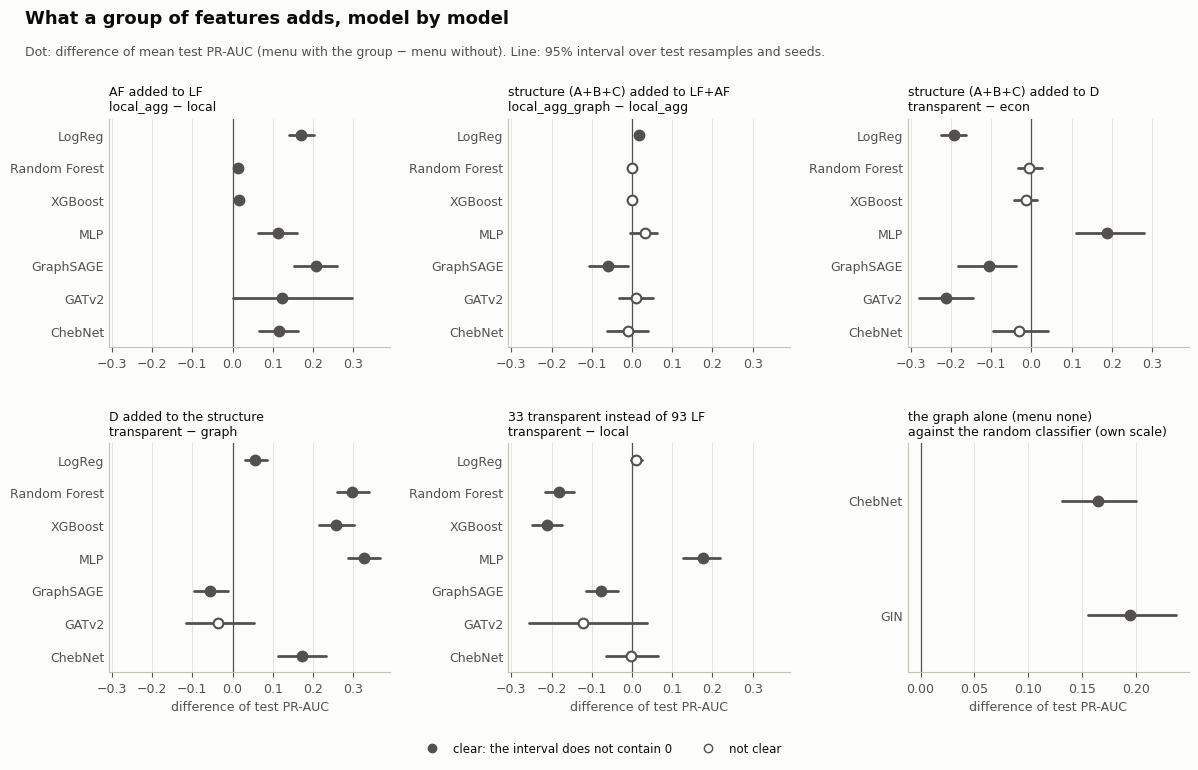

05_groups_added.png written (85 KB).


In [11]:
def forest(ax, rows):
    """rows: (label, difference, low, high). Filled dot = the interval does not contain 0."""
    for k, (label, d, low, high) in enumerate(rows):
        clear = low > 0 or high < 0
        ax.plot([low, high], [k, k], color=NEUTRAL, linewidth=2, solid_capstyle='round', zorder=2)
        ax.plot(d, k, 'o', markersize=7, markerfacecolor=NEUTRAL if clear else SURFACE, markeredgecolor=NEUTRAL,
                markeredgewidth=1.5, zorder=3)
    ax.axvline(0, color=INK_2, linewidth=0.9, zorder=1)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows])
    ax.set_ylim(len(rows) - 0.5, -0.5)
    light_grid(ax, 'x')
    ax.tick_params(axis='y', length=0)


def contrast_rows(kind, question):
    sel = CONTRASTS[(CONTRASTS['kind'] == kind) & (CONTRASTS['question'] == question) &
                    (CONTRASTS['metric'] == 'average_precision')]
    return [(MODEL_NAME[r.model], r.difference, r.interval_low, r.interval_high) for r in sel.itertuples()]


fig = plt.figure(figsize=(12, 7.8))
grid = fig.add_gridspec(2, 3, left=0.09, right=0.99, top=0.83, bottom=0.12, hspace=0.42, wspace=0.42)
group_axes = [fig.add_subplot(grid[k // 3, k % 3]) for k in range(5)]
for ax, (question, with_group, without) in zip(group_axes, ADDED):
    forest(ax, contrast_rows('group added', question))
    ax.set_title(f'{question}\n{with_group} − {without}', fontsize=9, loc='left')
lims = [ax.get_xlim() for ax in group_axes]
for ax in group_axes:
    ax.set_xlim(min(l[0] for l in lims), max(l[1] for l in lims))
group_axes[-1].set_xlabel('difference of test PR-AUC')
group_axes[3].set_xlabel('difference of test PR-AUC')
ax = fig.add_subplot(grid[1, 2])
forest(ax, contrast_rows('graph vs chance', 'graph alone - random classifier'))
ax.set_title('the graph alone (menu none)\nagainst the random classifier (own scale)', fontsize=9, loc='left')
ax.set_xlabel('difference of test PR-AUC')
fig.legend(handles=[Line2D([], [], marker='o', linestyle='', markerfacecolor=NEUTRAL, markeredgecolor=NEUTRAL,
                           label='clear: the interval does not contain 0'),
                    Line2D([], [], marker='o', linestyle='', markerfacecolor=SURFACE, markeredgecolor=NEUTRAL,
                           label='not clear')],
           loc='lower center', bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False, fontsize=8.5)
titles(fig, 'What a group of features adds, model by model',
       'Dot: difference of mean test PR-AUC (menu with the group − menu without). Line: 95% interval over test '
       'resamples and seeds.')
save_png(fig, '05_groups_added.png')

## 7. Plot 4 — does message passing help? (`05_message_passing.png`)

One panel per GNN, one row per menu: the difference of test PR-AUC between the GNN and the MLP **on the same menu**, with the two-level interval. The MLP sees the same columns but no edges, so the difference is what the graph adds beyond the features.

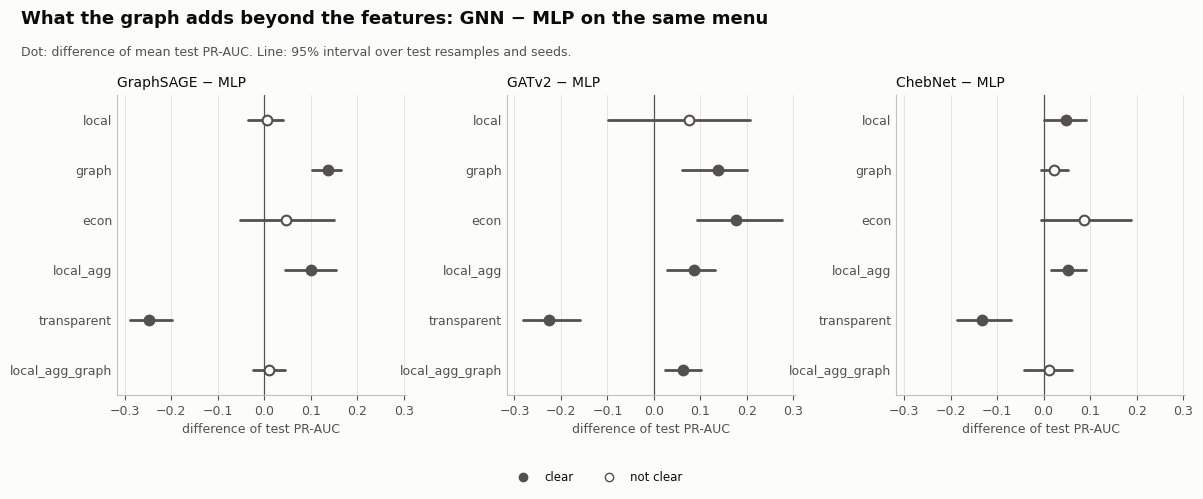

05_message_passing.png written (45 KB).


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharex=True)
fig.subplots_adjust(left=0.1, right=0.99, top=0.8, bottom=0.2, wspace=0.35)
for ax, gnn in zip(axes, GNNS):
    sel = CONTRASTS[(CONTRASTS['kind'] == 'message passing') & (CONTRASTS['model'] == gnn) &
                    (CONTRASTS['metric'] == 'average_precision')].set_index('side_a')
    forest(ax, [(menu, sel.loc[f'{menu}__{gnn}', 'difference'], sel.loc[f'{menu}__{gnn}', 'interval_low'],
                 sel.loc[f'{menu}__{gnn}', 'interval_high']) for menu in FEATURE_MENUS])
    ax.set_title(f'{MODEL_NAME[gnn]} − MLP', fontsize=10, loc='left')
    ax.set_xlabel('difference of test PR-AUC')
fig.legend(handles=[Line2D([], [], marker='o', linestyle='', markerfacecolor=NEUTRAL, markeredgecolor=NEUTRAL,
                           label='clear'),
                    Line2D([], [], marker='o', linestyle='', markerfacecolor=SURFACE, markeredgecolor=NEUTRAL,
                           label='not clear')],
           loc='lower center', bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False, fontsize=8.5)
titles(fig, 'What the graph adds beyond the features: GNN − MLP on the same menu',
       'Dot: difference of mean test PR-AUC. Line: 95% interval over test resamples and seeds.')
save_png(fig, '05_message_passing.png')

## 8. Plot 5 — training curves and overfitting (`05_learning_curves.png`)

Step 03 showed that the networks lose validation PR-AUC when the menu grows, while the trees do not. Left: the PR-AUC of train (every 10 epochs) and validation (every epoch) during the training of the MLP and of GraphSAGE (fixed in advance) on `local` and `local_agg_graph`, seed 0; the dashed line is the best epoch, the one that was kept. Right: the gap between train and validation PR-AUC of the kept model, mean over the seeds, for every model and menu (for the Random Forest the train value is the **out-of-bag** score, because on its own train rows it is almost always 1). A large gap means the model memorised the train.

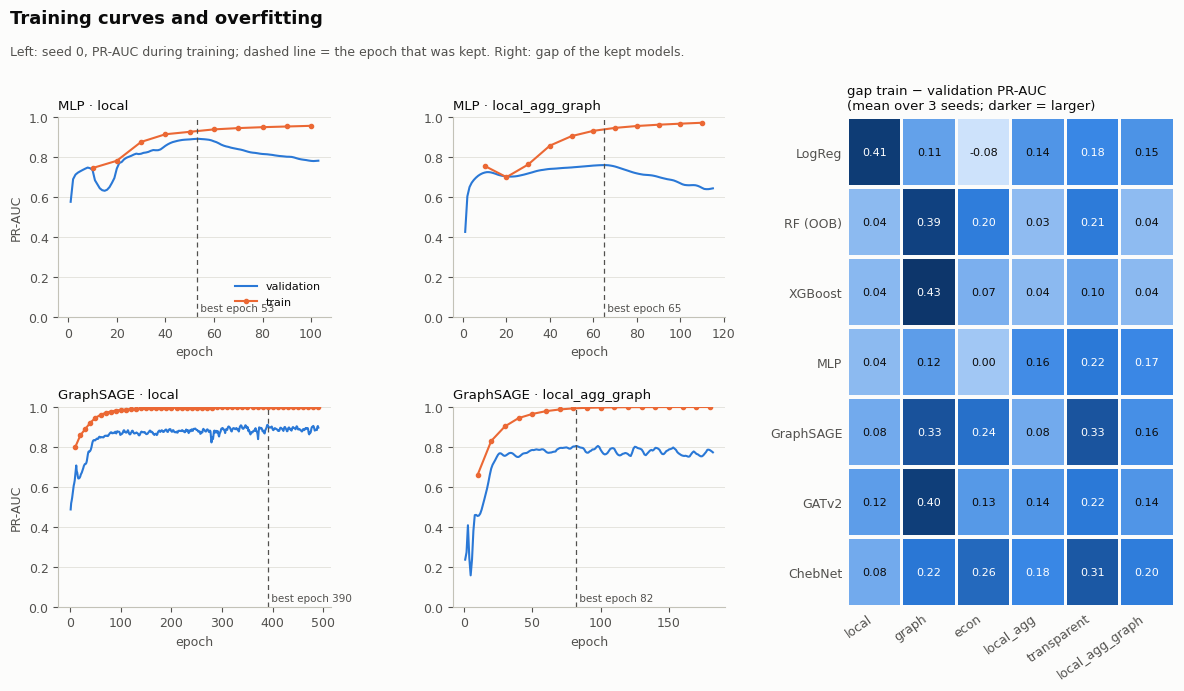

05_learning_curves.png written (117 KB).


In [13]:
fig = plt.figure(figsize=(12, 7.2))
grid = fig.add_gridspec(2, 3, left=0.06, right=0.99, top=0.82, bottom=0.14, hspace=0.45, wspace=0.42,
                        width_ratios=[1, 1, 1.2])
for i, model in enumerate(['mlp', CURVE_GNN]):
    for j, menu in enumerate(['local', 'local_agg_graph']):
        ax = fig.add_subplot(grid[i, j])
        tid = triple_id(menu, model, REFERENCE_SEED)
        curves = pd.read_csv(RUNS_DIR / 'curves' / f'{tid}.csv')
        ax.plot(curves['epoch'], curves['val_average_precision'], color=SERIES_2[0], linewidth=1.5, label='validation')
        train = curves.dropna(subset=['train_average_precision'])
        ax.plot(train['epoch'], train['train_average_precision'], color=SERIES_2[1], linewidth=1.5, marker='o',
                markersize=3, label='train')
        best = records[(menu, model, REFERENCE_SEED)]['training']['best_epoch']
        ax.axvline(best, color=INK_2, linewidth=0.9, linestyle=(0, (4, 3)))
        ax.text(best, 0.02, f' best epoch {best}', fontsize=7.5, color=INK_2, va='bottom')
        ax.set_ylim(0, 1)
        ax.set_title(f'{MODEL_NAME[model]} · {menu}', fontsize=9.5, loc='left')
        ax.set_xlabel('epoch')
        if j == 0:
            ax.set_ylabel('PR-AUC')
        light_grid(ax)
        if i == 0 and j == 0:
            ax.legend(frameon=False, fontsize=8, loc='lower right')

gap_models = [m for m in MODELS if m != 'gin']
gap = np.full((len(gap_models), len(FEATURE_MENUS)), np.nan)
for a, model in enumerate(gap_models):
    for b, menu in enumerate(FEATURE_MENUS):
        sel = RUNS[(RUNS['menu'] == menu) & (RUNS['model'] == model)]
        train_value = sel['oob_ap'] if model == 'rf' else sel['train_ap']
        gap[a, b] = (train_value - sel['val_ap']).mean()
ax = fig.add_subplot(grid[:, 2])
gnorm = Normalize(np.nanmin(gap), np.nanmax(gap))
for a in range(len(gap_models)):
    for b in range(len(FEATURE_MENUS)):
        color = BLUE_CMAP(gnorm(gap[a, b]))
        ax.add_patch(Rectangle((b + 0.03, a + 0.03), 0.94, 0.94, facecolor=color, edgecolor='none'))
        label = f'{gap[a, b]:.2f}'.replace('-0.00', '0.00')
        ax.text(b + 0.5, a + 0.5, label, ha='center', va='center', fontsize=8, color=text_color_on(color))
ax.set_xlim(0, len(FEATURE_MENUS))
ax.set_ylim(len(gap_models), 0)
ax.set_xticks(np.arange(len(FEATURE_MENUS)) + 0.5, FEATURE_MENUS, rotation=35, ha='right')
ax.set_yticks(np.arange(len(gap_models)) + 0.5, ['RF (OOB)' if m == 'rf' else MODEL_NAME[m] for m in gap_models])
ax.tick_params(length=0)
for side in ['left', 'bottom']:
    ax.spines[side].set_visible(False)
ax.set_title('gap train − validation PR-AUC\n(mean over 3 seeds; darker = larger)', fontsize=9.5, loc='left')
titles(fig, 'Training curves and overfitting',
       f'Left: seed {REFERENCE_SEED}, PR-AUC during training; dashed line = the epoch that was kept. '
       'Right: gap of the kept models.')
save_png(fig, '05_learning_curves.png')

## 9. Plot 6 — precision-recall curves (`05_pr_curves.png`)

One panel per menu, with the model chosen on validation for that menu (seed 0, fixed in advance): precision against recall on the test. The other menus are drawn in light grey, for reference; the dashed line is the random classifier. The interesting part is on the left, at high precision: an analyst cares most about the first transactions flagged.

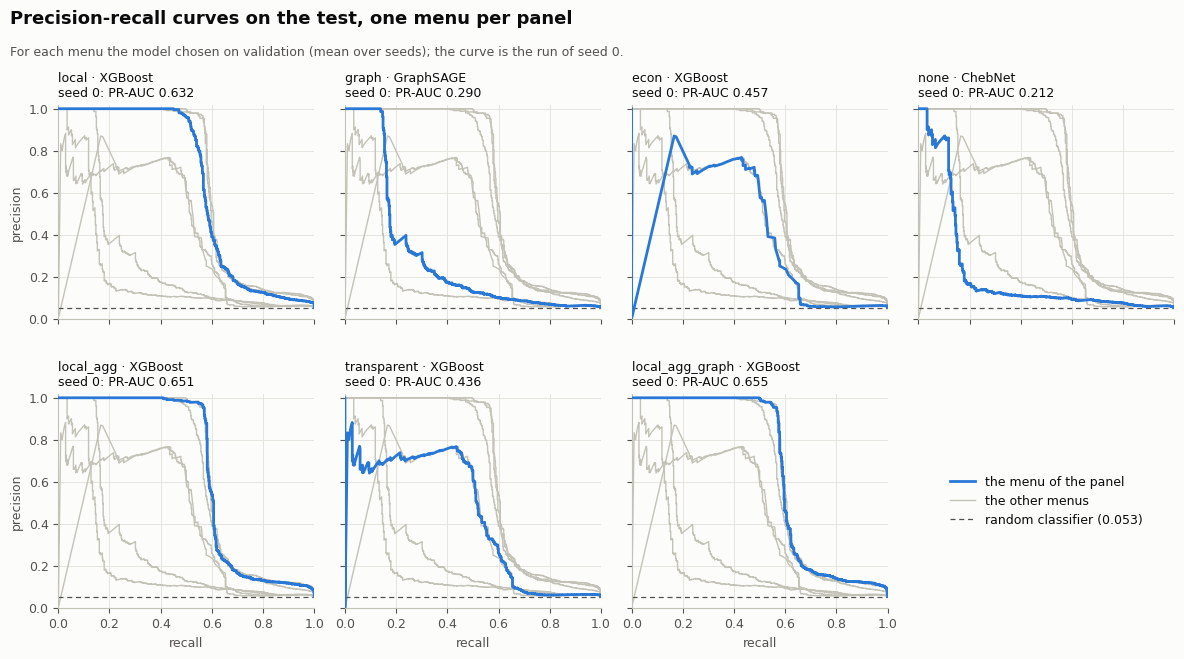

05_pr_curves.png written (177 KB).


In [14]:
def pr_curve(menu, model, seed=REFERENCE_SEED):
    table = pd.read_parquet(RUNS_DIR / 'predictions' / f'{triple_id(menu, model, seed)}.parquet')
    test = table[table['split'] == 'test']
    precision, recall, _ = precision_recall_curve(test['y'].to_numpy(), test['score'].to_numpy())
    return recall, precision, average_precision_score(test['y'].to_numpy(), test['score'].to_numpy())


CURVES = {menu: pr_curve(menu, CHOSEN[menu]) for menu in MENU_ORDER}
fig, axes = plt.subplots(2, 4, figsize=(12, 6.8), sharex=True, sharey=True)
fig.subplots_adjust(left=0.06, right=0.99, top=0.83, bottom=0.09, hspace=0.35, wspace=0.12)
for ax, menu in zip(axes.flat, MENU_ORDER):
    for other in MENU_ORDER:
        if other != menu:
            ax.plot(CURVES[other][0], CURVES[other][1], color=AXIS, linewidth=1, zorder=1)
    recall, precision, ap = CURVES[menu]
    ax.plot(recall, precision, color=SERIES_2[0], linewidth=2, zorder=3)
    ax.axhline(PREVALENCE['test'], color=INK_2, linewidth=0.9, linestyle=(0, (4, 3)), zorder=2)
    ax.set_title(f'{menu} · {MODEL_NAME[CHOSEN[menu]]}\nseed {REFERENCE_SEED}: PR-AUC {ap:.3f}', fontsize=9, loc='left')
    light_grid(ax, 'both')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
for ax in axes[1]:
    ax.set_xlabel('recall')
for ax in axes[:, 0]:
    ax.set_ylabel('precision')
legend_ax = axes.flat[-1]
legend_ax.axis('off')
legend_ax.legend(handles=[Line2D([], [], color=SERIES_2[0], linewidth=2, label='the menu of the panel'),
                          Line2D([], [], color=AXIS, linewidth=1, label='the other menus'),
                          Line2D([], [], color=INK_2, linewidth=0.9, linestyle=(0, (4, 3)),
                                 label=f"random classifier ({PREVALENCE['test']:.3f})")],
                 loc='center', frameon=False, fontsize=9)
titles(fig, 'Precision-recall curves on the test, one menu per panel',
       'For each menu the model chosen on validation (mean over seeds); the curve is the run of seed 0.')
save_png(fig, '05_pr_curves.png')

## 10. Plot 7 — the analyst's view: top-k (`05_topk.png`)

An analyst sorts the test transactions by score and checks the first $k$. **recall@k** = the share of the 524 illicit transactions of the test found among those $k$. For $k$ = 100 (about 1% of the test), 524 (as many as the illicit) and 987 (10% of the test), for the model chosen on validation of each menu, mean over the seeds ± standard deviation. The black tick over each bar is the best possible value: with $k = 100$ at most 100 of the 524 illicit can be found (recall 0.19).

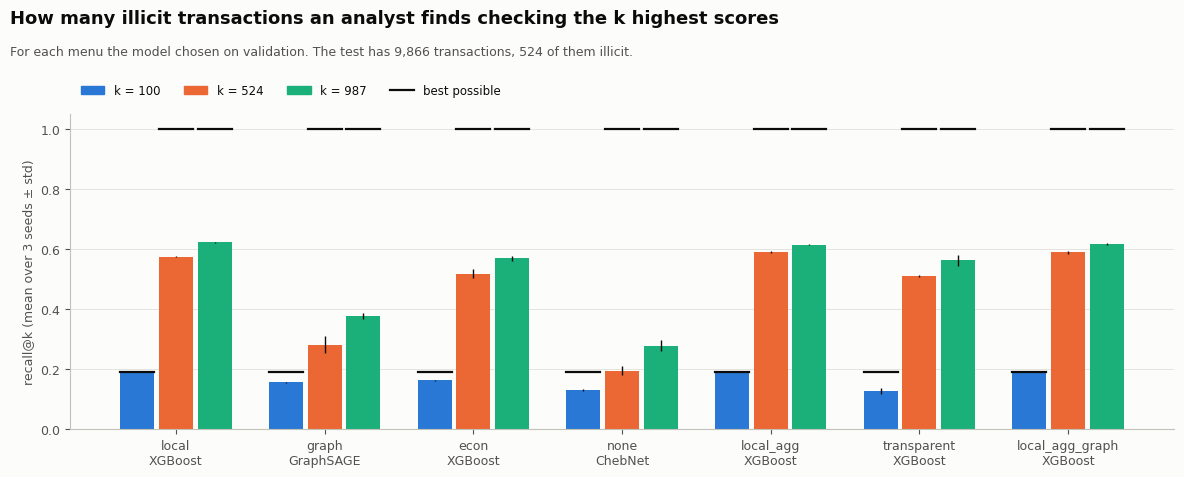

05_topk.png written (44 KB).


In [15]:
fig, ax = plt.subplots(figsize=(12, 5))
fig.subplots_adjust(left=0.07, right=0.99, top=0.76, bottom=0.13)
width = 0.26
for j, menu in enumerate(MENU_ORDER):
    s = STATS.loc[(menu, CHOSEN[menu])]
    for k_index, k in enumerate(TOPK_KS):
        x = j + (k_index - 1) * width
        ax.bar(x, s[f'recall_at_{k}_mean'], width * 0.88, color=SERIES_2[k_index], zorder=2)
        ax.errorbar(x, s[f'recall_at_{k}_mean'], yerr=s[f'recall_at_{k}_std'], fmt='none', ecolor=INK, elinewidth=1,
                    zorder=3)
        ceiling = min(k, Y_TEST.sum()) / Y_TEST.sum()
        ax.plot([x - width * 0.44, x + width * 0.44], [ceiling, ceiling], color=INK, linewidth=1.6, zorder=4)
ax.set_xticks(range(len(MENU_ORDER)), [f'{menu}\n{MODEL_NAME[CHOSEN[menu]]}' for menu in MENU_ORDER])
ax.set_ylim(0, 1.05)
ax.set_ylabel('recall@k (mean over 3 seeds ± std)')
light_grid(ax)
ax.legend(handles=[Patch(color=SERIES_2[i], label=f'k = {k}') for i, k in enumerate(TOPK_KS)] +
          [Line2D([], [], color=INK, linewidth=1.6, label='best possible')],
          ncol=4, frameon=False, loc='lower left', bbox_to_anchor=(0, 1.02), fontsize=8.5)
titles(fig, 'How many illicit transactions an analyst finds checking the k highest scores',
       'For each menu the model chosen on validation. The test has 9,866 transactions, 524 of them illicit.')
save_png(fig, '05_topk.png')

## 11. Plot 8 — validation against test (`05_val_vs_test.png`)

Left and centre: one dot per triple, the PR-AUC and the ROC-AUC on validation against the test. The prevalence halves from validation (0.113) to test (0.053), and the PR-AUC depends on the prevalence, so most dots sit under the diagonal even without overfitting; the ROC-AUC does not depend on the prevalence and shows the real change of difficulty. Right: one dot per pair, the validation PR-AUC of the best trial of the tuning against the mean of the final runs: the tuning picks the best of many trials, so it is a little optimistic.

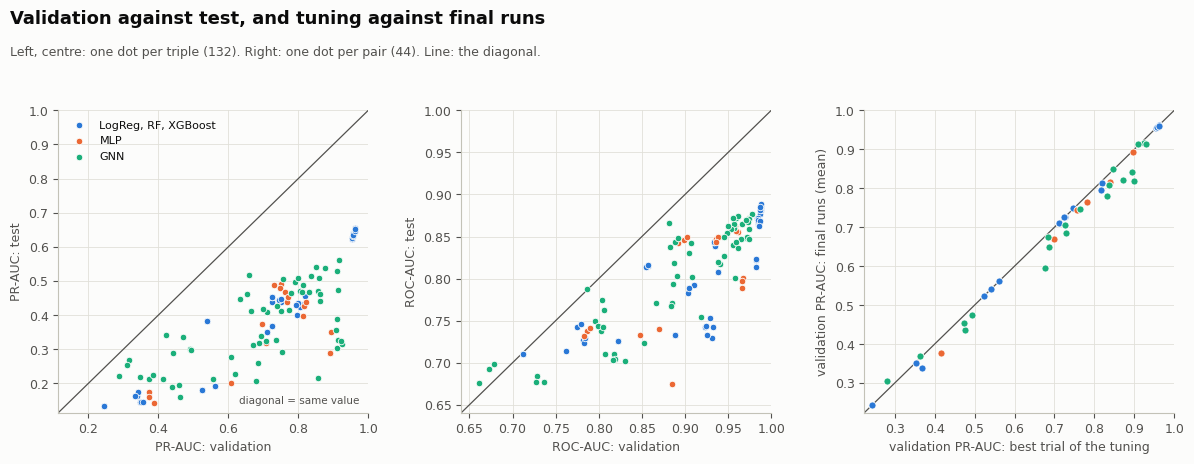

05_val_vs_test.png written (84 KB).


In [16]:
tuning = pd.read_csv(TUNING_DIR / 'summary.csv').set_index(['menu', 'model'])
fig, axes = plt.subplots(1, 3, figsize=(12, 4.8))
fig.subplots_adjust(left=0.06, right=0.99, top=0.76, bottom=0.13, wspace=0.3)
panels = [('val_ap', 'test_ap', 'PR-AUC: validation', 'PR-AUC: test'),
          ('val_roc', 'test_roc', 'ROC-AUC: validation', 'ROC-AUC: test')]
for ax, (x_col, y_col, x_label, y_label) in zip(axes[:2], panels):
    for group, color in GROUP_COLOR.items():
        sel = RUNS[RUNS['model'].map(GROUP_OF) == group]
        ax.scatter(sel[x_col], sel[y_col], s=22, color=color, edgecolor=SURFACE, linewidth=0.6, label=group, zorder=3)
    low = min(RUNS[x_col].min(), RUNS[y_col].min()) - 0.02
    ax.plot([low, 1], [low, 1], color=INK_2, linewidth=0.9, zorder=1)
    ax.set_xlim(low, 1)
    ax.set_ylim(low, 1)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    light_grid(ax, 'both')
axes[0].text(0.97, 0.03, 'diagonal = same value', transform=axes[0].transAxes, ha='right', fontsize=7.5, color=INK_2)
ax = axes[2]
for group, color in GROUP_COLOR.items():
    xs, ys = [], []
    for menu, model in PAIRS:
        if GROUP_OF[model] == group:
            xs.append(tuning.loc[(menu, model), 'val_average_precision'])
            ys.append(STATS.loc[(menu, model), 'val_ap_mean'])
    ax.scatter(xs, ys, s=26, color=color, edgecolor=SURFACE, linewidth=0.6, zorder=3)
low = min(tuning['val_average_precision'].min(), RUNS['val_ap'].min()) - 0.02
ax.plot([low, 1], [low, 1], color=INK_2, linewidth=0.9, zorder=1)
ax.set_xlim(low, 1)
ax.set_ylim(low, 1)
ax.set_xlabel('validation PR-AUC: best trial of the tuning')
ax.set_ylabel('validation PR-AUC: final runs (mean)')
light_grid(ax, 'both')
axes[0].legend(frameon=False, fontsize=8, loc='upper left')
titles(fig, 'Validation against test, and tuning against final runs',
       'Left, centre: one dot per triple (132). Right: one dot per pair (44). Line: the diagonal.')
save_png(fig, '05_val_vs_test.png')

## 12. Plot 9 — which transactions does the graph rescue? (`05_gnn_rescues.png`)

For every menu and GNN (seed 0), compare the 524 test transactions with the highest scores of the GNN with those of the MLP on the same menu:
- **rescued**: illicit transactions in the top 524 of the GNN but not of the MLP; **lost**: the opposite.

Left: rescued (to the right) and lost (to the left) for each pair. Right: who the neighbours of these transactions are, in the graph of the test (edges taken in both directions): the share of illicit, licit and unknown neighbours, averaged over the transactions of each set and then over the 18 (menu, GNN) pairs. If the GNN rescues transactions with many illicit neighbours, it is using the graph as expected. The counts are in `rescues.csv`.

rescues.csv written.


,menu,gnn,GNN only (rescued) count,MLP only (lost) count,both count,neither count
0,local,sage,19,33,249,223
1,local,gatv2,19,63,219,223
2,local,cheb,18,17,265,224
3,graph,sage,90,47,68,319
4,graph,gatv2,93,40,75,316
5,graph,cheb,51,32,83,358
6,econ,sage,27,72,196,229
7,econ,gatv2,27,25,243,229
8,econ,cheb,18,33,235,238
9,local_agg,sage,45,2,245,232


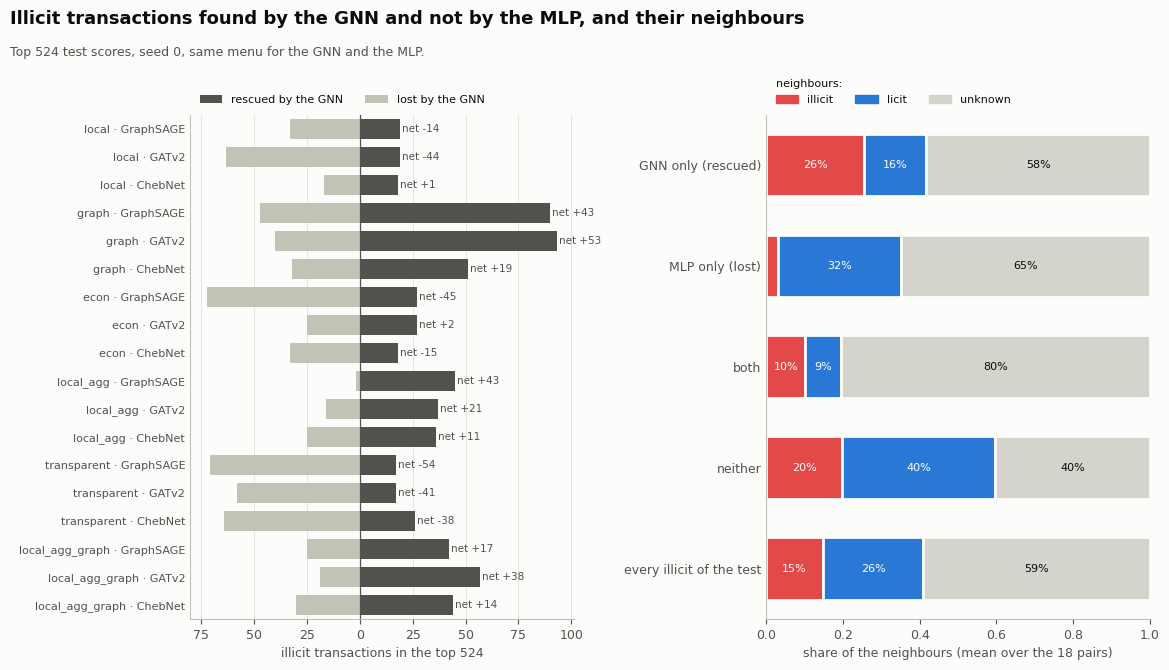

05_gnn_rescues.png written (96 KB).


In [17]:
dataset = pd.read_parquet(INPUT_DIR / 'dataset.parquet', columns=['split', 'y'])
edges = pd.read_parquet(INPUT_DIR / 'edges.parquet')
y_all = dataset['y'].to_numpy(dtype=np.float64, na_value=np.nan)
cls = np.where(np.isnan(y_all), 2, np.where(y_all == 1, 0, 1))      # 0 illicit, 1 licit, 2 unknown
src, dst = edges['src_row'].to_numpy(np.int64), edges['dst_row'].to_numpy(np.int64)
neighbour_counts = np.zeros((len(dataset), 3))
np.add.at(neighbour_counts, (src, cls[dst]), 1)
np.add.at(neighbour_counts, (dst, cls[src]), 1)
degree = neighbour_counts.sum(axis=1)


def top_illicit(menu, model, k):
    table = pd.read_parquet(RUNS_DIR / 'predictions' / f'{triple_id(menu, model, REFERENCE_SEED)}.parquet')
    test = table[table['split'] == 'test']
    order = np.argsort(-test['score'].to_numpy(), kind='stable')[:k]
    top = test.iloc[order]
    return set(top.loc[top['y'] == 1, 'row']), set(test.loc[test['y'] == 1, 'row'])


def composition(rows):
    rows = np.array(sorted(r for r in rows if degree[r] > 0), dtype=np.int64)
    if len(rows) == 0:
        return np.full(3, np.nan)
    return (neighbour_counts[rows] / degree[rows, None]).mean(axis=0)


K = int(Y_TEST.sum())
rows, compositions = [], {name: [] for name in ['GNN only (rescued)', 'MLP only (lost)', 'both', 'neither']}
for menu in FEATURE_MENUS:
    mlp_found, all_illicit = top_illicit(menu, 'mlp', K)
    for gnn in GNNS:
        gnn_found, _ = top_illicit(menu, gnn, K)
        sets = {'GNN only (rescued)': gnn_found - mlp_found, 'MLP only (lost)': mlp_found - gnn_found,
                'both': gnn_found & mlp_found, 'neither': all_illicit - gnn_found - mlp_found}
        row = {'menu': menu, 'gnn': gnn, 'k': K}
        for name, nodes in sets.items():
            comp = composition(nodes)
            compositions[name].append(comp)
            row[f'{name} count'] = len(nodes)
            for c, label in enumerate(['illicit', 'licit', 'unknown']):
                row[f'{name} share {label} neighbours'] = comp[c]
        rows.append(row)
RESCUES = pd.DataFrame(rows)
save_table(RESCUES.round(4), 'rescues.csv', show=False)
display(RESCUES[['menu', 'gnn'] + [c for c in RESCUES.columns if c.endswith('count')]])
reference = composition(set(np.flatnonzero((dataset['split'].to_numpy() == 'test') & (y_all == 1))))

fig = plt.figure(figsize=(12, 7))
grid = fig.add_gridspec(1, 2, left=0.17, right=0.97, top=0.82, bottom=0.1, wspace=0.5, width_ratios=[1, 1])
ax = fig.add_subplot(grid[0])
labels = [f'{r.menu} · {MODEL_NAME[r.gnn]}' for r in RESCUES.itertuples()]
y_pos = np.arange(len(RESCUES))
ax.barh(y_pos, RESCUES['GNN only (rescued) count'], height=0.7, color=NEUTRAL, zorder=2, label='rescued by the GNN')
ax.barh(y_pos, -RESCUES['MLP only (lost) count'], height=0.7, color=AXIS, zorder=2, label='lost by the GNN')
for k, (rescued, lost) in enumerate(zip(RESCUES['GNN only (rescued) count'], RESCUES['MLP only (lost) count'])):
    ax.text(rescued + 1, k, f'net {rescued - lost:+d}', va='center', fontsize=7.5, color=INK_2)
ax.axvline(0, color=INK_2, linewidth=0.9)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{abs(v):.0f}'))
ax.set_yticks(y_pos, labels, fontsize=8)
ax.set_ylim(len(RESCUES) - 0.5, -0.5)
ax.set_xlabel(f'illicit transactions in the top {K}')
light_grid(ax, 'x')
ax.tick_params(axis='y', length=0)
ax.legend(frameon=False, fontsize=8, loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2)

ax = fig.add_subplot(grid[1])
names = list(compositions) + ['every illicit of the test']
values = [np.nanmean(np.vstack(compositions[n]), axis=0) for n in compositions] + [reference]
for k, (name, comp) in enumerate(zip(names, values)):
    left = 0.0
    for c, label in enumerate(['illicit', 'licit', 'unknown']):
        ax.barh(k, comp[c], left=left, height=0.62, color=CLASS_COLOR[label], edgecolor=SURFACE, linewidth=2)
        if comp[c] > 0.07:
            ax.text(left + comp[c] / 2, k, f'{comp[c]:.0%}', ha='center', va='center', fontsize=8,
                    color='white' if label != 'unknown' else INK)
        left += comp[c]
ax.set_yticks(range(len(names)), names)
ax.set_ylim(len(names) - 0.5, -0.5)
ax.set_xlim(0, 1)
ax.set_xlabel('share of the neighbours (mean over the 18 pairs)')
ax.tick_params(axis='y', length=0)
ax.legend(handles=[Patch(color=CLASS_COLOR[c], label=c) for c in ['illicit', 'licit', 'unknown']],
          ncol=3, frameon=False, fontsize=8, loc='lower left', bbox_to_anchor=(0, 1.0), title='neighbours:',
          title_fontsize=8, alignment='left')
titles(fig, 'Illicit transactions found by the GNN and not by the MLP, and their neighbours',
       f'Top {K} test scores, seed {REFERENCE_SEED}, same menu for the GNN and the MLP.')
save_png(fig, '05_gnn_rescues.png')

## 13. Files written

Every table is in `05-plots/` and every plot in `plots/`, with the prefix `05_`.

In [18]:
for path in sorted(OUT_DIR.glob('*.csv')):
    print(f'{path.name:24s} {path.stat().st_size / 1e3:8.1f} KB')
for path in sorted(PLOT_DIR.glob('05_*.png')):
    print(f'{path.name:28s} {path.stat().st_size / 1e3:8.1f} KB')
drive.flush_and_unmount()

best_per_menu.csv             0.8 KB
contrasts.csv                16.1 KB
rescues.csv                   2.5 KB
results_table.csv             6.2 KB
05_gnn_rescues.png               96.1 KB
05_groups_added.png              85.1 KB
05_learning_curves.png          116.6 KB
05_message_passing.png           45.1 KB
05_pr_curves.png                177.2 KB
05_results_bars.png              54.9 KB
05_results_heatmap.png          114.6 KB
05_topk.png                      43.8 KB
05_val_vs_test.png               83.6 KB
